### Importing Libraries 

In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

### Creating a dataframe

In [33]:
df = pd.read_csv("expenses.csv")
print(df.head(1))

         Date Category  Amount Payment_Method
0  2026-10-01     Food     250            UPI


In [34]:
df.shape

(15, 4)

In [35]:
df.info

<bound method DataFrame.info of           Date       Category  Amount Payment_Method
0   2026-10-01           Food     250            UPI
1   2026-10-02         Travel     120           Cash
2   2026-10-03           Food     180            UPI
3   2026-10-04       Shopping     900           Card
4   2026-10-05      Education     500            UPI
5   2026-10-06         Travel      80           Cash
6   2026-10-07           Food     300            UPI
7   2026-10-08  Entertainment     400           Card
8   2026-10-09      Education     250            UPI
9   2026-10-10       Shopping     600            UPI
10  2026-10-11           Food     150           Cash
11  2026-10-12         Travel     100            UPI
12  2026-10-13  Entertainment     200           Cash
13  2026-10-14           Food     220            UPI
14  2026-10-15       Shopping     350           Card>

In [36]:
df.describe

<bound method NDFrame.describe of           Date       Category  Amount Payment_Method
0   2026-10-01           Food     250            UPI
1   2026-10-02         Travel     120           Cash
2   2026-10-03           Food     180            UPI
3   2026-10-04       Shopping     900           Card
4   2026-10-05      Education     500            UPI
5   2026-10-06         Travel      80           Cash
6   2026-10-07           Food     300            UPI
7   2026-10-08  Entertainment     400           Card
8   2026-10-09      Education     250            UPI
9   2026-10-10       Shopping     600            UPI
10  2026-10-11           Food     150           Cash
11  2026-10-12         Travel     100            UPI
12  2026-10-13  Entertainment     200           Cash
13  2026-10-14           Food     220            UPI
14  2026-10-15       Shopping     350           Card>

In [37]:
df.isnull().sum()

Date              0
Category          0
Amount            0
Payment_Method    0
dtype: int64

### Calculate expenses

In [38]:
total_expenses = df['Amount'].sum()
avg_expenses = df['Amount'].mean()
highest_expenses = df['Amount'].max()
lowest_expenses = df['Amount'].min()

print(total_expenses)
print(avg_expenses)
print(highest_expenses)
print(lowest_expenses)

4600
306.6666666666667
900
80


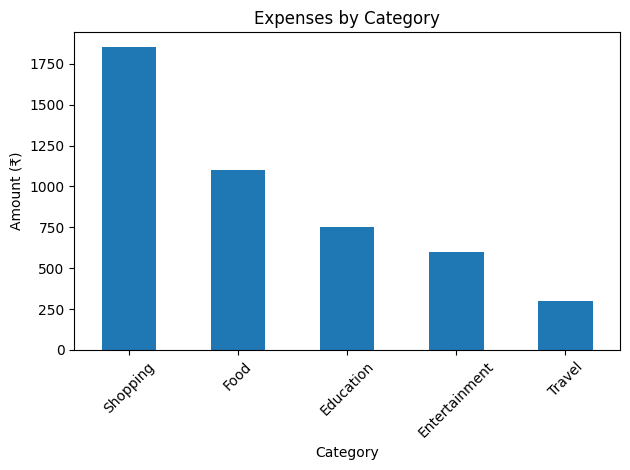

In [39]:
category_expense = df.groupby("Category")["Amount"].sum()
category_expense = category_expense.sort_values(ascending=False)
category_expense.plot(kind="bar")
plt.title("Expenses by Category")
plt.xlabel("Category")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [40]:
payment_expenses = df.groupby("Payment_Method")["Amount"].sum().sort_values(ascending=False)
print(payment_expenses)
                


Payment_Method
UPI     2400
Card    1650
Cash     550
Name: Amount, dtype: int64


In [41]:
filtered_df = df[(df['Amount'] > 300) & (df['Category'] == 'Shopping')]
filtered_df.sum()

Date              2026-10-042026-10-102026-10-15
Category                ShoppingShoppingShopping
Amount                                      1850
Payment_Method                       CardUPICard
dtype: object

In [42]:
print("===== PERSONAL EXPENSE REPORT =====")
print(f"Total expenses: ₹{total_expenses:.2f}")
print(f"Average transaction: ₹{avg_expenses:.2f}")

print("\nSpending by category:")
print(category_expense.sort_values(ascending=False))

print("\nSpending by payment method:")
print(payment_expenses.sort_values(ascending=False))

print("\nHighest spending category:",
      category_expense.idxmax())

print("Lowest spending category:",
      category_expense.idxmin())

===== PERSONAL EXPENSE REPORT =====
Total expenses: ₹4600.00
Average transaction: ₹306.67

Spending by category:
Category
Shopping         1850
Food             1100
Education         750
Entertainment     600
Travel            300
Name: Amount, dtype: int64

Spending by payment method:
Payment_Method
UPI     2400
Card    1650
Cash     550
Name: Amount, dtype: int64

Highest spending category: Shopping
Lowest spending category: Travel


### Professional Spending Dashboard 

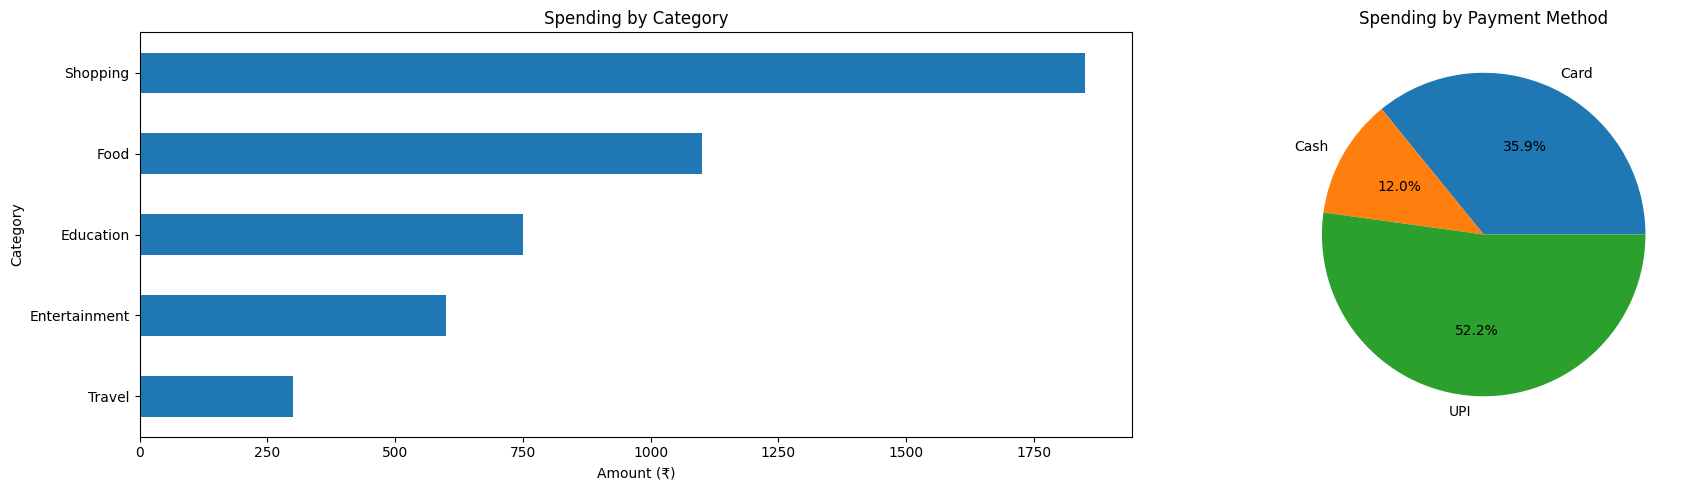

In [47]:

import matplotlib.pyplot as plt

category_expense = df.groupby("Category")["Amount"].sum()
payment_expense = df.groupby("Payment_Method")["Amount"].sum()

fig, axes = plt.subplots(1, 2, figsize=(20, 5))

category_expense.sort_values().plot(
    kind="barh", ax=axes[0], title="Spending by Category"
)
axes[0].set_xlabel("Amount (₹)")
axes[0].set_ylabel("Category")

payment_expense.plot(
    kind="pie",
    autopct="%1.1f%%",
    ax=axes[1],
    title="Spending by Payment Method"
)
axes[1].set_ylabel("")

plt.tight_layout()
plt.savefig("expense_dashboard.png", dpi=300, bbox_inches="tight")

plt.show()


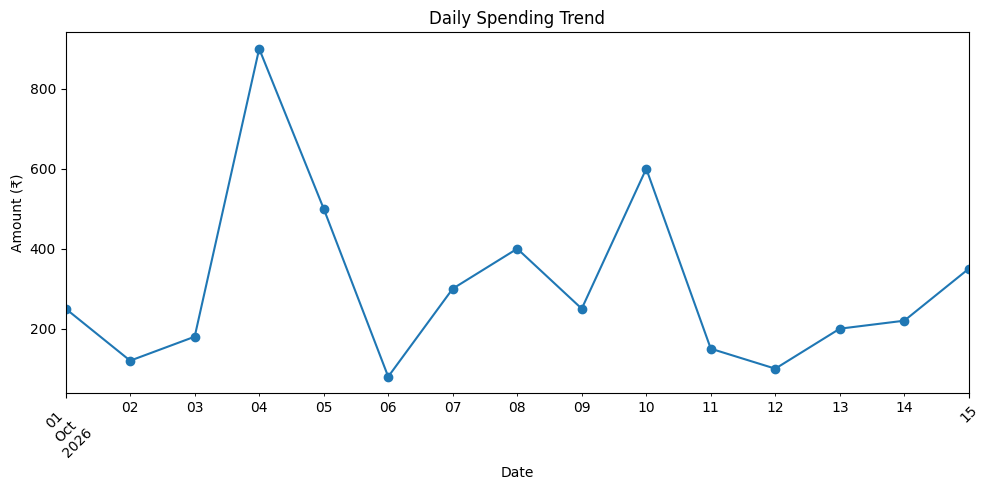

In [53]:

df["Date"] = pd.to_datetime(df["Date"])

daily_expense = df.groupby("Date")["Amount"].sum()

daily_expense.plot(
    kind="line",
    marker="o",
    figsize=(10, 5),
    title="Daily Spending Trend"
)

plt.xlabel("Date")
plt.ylabel("Amount (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("daily_expense.png", dpi=600, bbox_inches="tight")

plt.show()
